# Optical-Pump Scan Analysis (1-D or 2-D)

Interactive analysis of `OpticalPumpScan` runs. The scan has two dashboard-selectable axes
(X, Y) chosen from `{t_optical_pump, f_pump_repumper, amp_pump_repumper_active}` (Y='none' -> 1-D).
Reuses the BLAS-free helpers from `analyze_optical_pump_scan.py`.

At each grid point: interleaved pi / no-pi configs. Among loaded atoms `lost = 1 - retention`
(atom ended in F=4 -> blown away). The clean mF=0 signal subtracts the F=4-leftover background:
**`signal = lost_pi - lost_noPi`** (`lost_noPi` = the repumper's F=4 leftover -- the thing to drive down).

- **1-D** (Y='none'): lost-fraction + signal vs X; a saturating fit + recommended time when X is the pump time.
- **2-D**: heatmaps of `signal` (maximize) and `lost_noPi` (minimize); best cell = argmax signal.

Run with the **working-BLAS `python`** kernel (numpy / h5py / mpl).

In [368]:
import sys, os, glob
from pathlib import Path
_ANALYSIS_DIR = r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\analysis"
if _ANALYSIS_DIR not in sys.path:
    sys.path.insert(0, _ANALYSIS_DIR)
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%load_ext autoreload
%autoreload 2
from analyze_optical_pump_scan import (
    RESULTS_DIR, find_run, load_run, get_xy, axis_label,
    retention_table, build_curves, build_grids_2d,
    fit_saturation, empirical_knee, wilson,
)
print("Results dir:", RESULTS_DIR)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Results dir: C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results


## 1. List recent runs

In [369]:
files = sorted(glob.glob(str(RESULTS_DIR / "**" / "*-OpticalPumpScan.h5"), recursive=True),
               key=lambda f: int(os.path.basename(f).split("-")[0]))
if not files:
    print("No *-OpticalPumpScan.h5 found yet.")
for f in files[-12:]:
    rid = int(os.path.basename(f).split("-")[0])
    d, s, _ = load_run(f)
    n = len(np.atleast_1d(d.get("op_axis_x_val", d.get("op_t_pump_us", []))))
    nl = int(np.sum(np.atleast_1d(d.get("op_atom_loaded", [0])).astype(int)))
    print(f"RID {rid:>5} | {n:>6} pts | {nl:>5} loaded | "
          f"X={s.get('axis_x','t_optical_pump')}  Y={s.get('axis_y','none')}")

RID   640 |   2376 pts |  2296 loaded | X=t_optical_pump  Y=none
RID   680 |   4104 pts |  3894 loaded | X=f_pump_repumper  Y=amp_pump_repumper_active
RID   685 |   1400 pts |  1368 loaded | X=amp_pump_repumper_active  Y=none
RID   689 |    378 pts |   346 loaded | X=f_pump_repumper  Y=none
RID   692 |   2200 pts |  1923 loaded | X=f_pump_repumper  Y=none
RID   696 |   1400 pts |  1267 loaded | X=t_optical_pump  Y=none
RID   702 |   3060 pts |  2961 loaded | X=amp_pump_D1  Y=t_optical_pump
RID   707 |   1100 pts |  1084 loaded | X=f_pump_D1  Y=none
RID   710 |   1100 pts |  1088 loaded | X=t_optical_pump  Y=none
RID   720 |   4400 pts |  3958 loaded | X=t_optical_pump  Y=none


## 2. Select a run

Set `RID` to an int, or `None` for the latest.

In [370]:
RID = None   # <-- int or None (latest)

path = find_run(RID)
data, snap, rid = load_run(path)
x, y, x_name, y_name = get_xy(data, snap)
n_x = len({round(float(v), 4) for v in x})
n_y = len({round(float(v), 4) for v in y})
mode = "2d" if n_y > 1 else "1d"
n_loaded = int(np.sum(np.atleast_1d(data.get('op_atom_loaded', [0])).astype(int)))
print("File :", os.path.basename(path))
print(f"RID {rid} | X={x_name} ({n_x})  Y={y_name} ({n_y})  ->  {mode.upper()} | loaded={n_loaded}")

File : 000000720-OpticalPumpScan.h5
RID 720 | X=t_optical_pump (11)  Y=none (1)  ->  1D | loaded=3958


## 3. 1-D view (runs when Y='none')

Lost fraction (pi vs no-pi) + clean signal vs X; saturating fit + recommended time when X is the pump time.

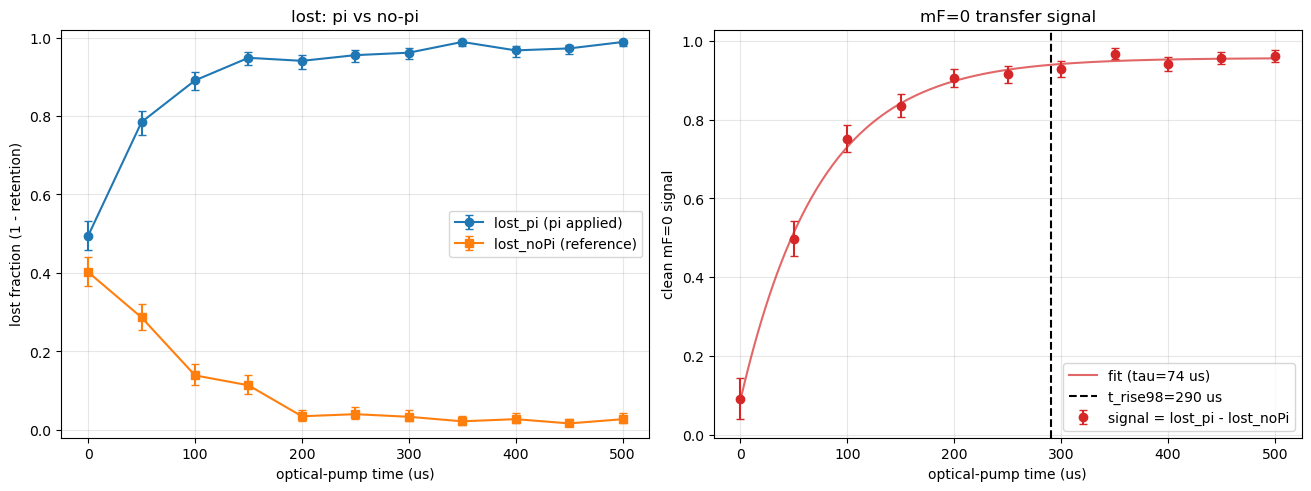

Best fidelity:0.967
RECOMMENDED t_optical_pump ~ 290.3 us (set it yourself; not written).


In [371]:
if mode == "1d":
    curves = build_curves(data, snap)
    ts = curves["ts"]
    is_time = (x_name == "t_optical_pump")
    fit = fit_saturation(ts, curves["signal"], weights=curves["n_eff"]) if is_time else {"ok": False}
    knee = empirical_knee(curves)
    fig, (axL, axS) = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
    axL.errorbar(ts, curves["lost_pi"],
                 yerr=[np.nan_to_num(curves["lost_pi"]-curves["lpi_lo"]), np.nan_to_num(curves["lpi_hi"]-curves["lost_pi"])],
                 fmt="o-", color="C0", capsize=3, label="lost_pi (pi applied)")
    axL.errorbar(ts, curves["lost_no"],
                 yerr=[np.nan_to_num(curves["lost_no"]-curves["lno_lo"]), np.nan_to_num(curves["lno_hi"]-curves["lost_no"])],
                 fmt="s-", color="C1", capsize=3, label="lost_noPi (reference)")
    axL.set_xlabel(axis_label(x_name)); axL.set_ylabel("lost fraction (1 - retention)")
    axL.set_ylim(-0.02, 1.02); axL.legend(); axL.grid(alpha=0.3); axL.set_title("lost: pi vs no-pi")
    sig_half = np.sqrt(np.nan_to_num((curves["lpi_hi"]-curves["lpi_lo"])/2.0)**2
                       + np.nan_to_num((curves["lno_hi"]-curves["lno_lo"])/2.0)**2)
    axS.errorbar(ts, curves["signal"], yerr=sig_half, fmt="o", color="C3", capsize=3, label="signal = lost_pi - lost_noPi")
    if is_time and fit.get("ok"):
        tt = np.linspace(0.0, max(ts), 300); yy = fit["S_inf"]-(fit["S_inf"]-fit["S0"])*np.exp(-tt/fit["tau"])
        axS.plot(tt, yy, "-", color="C3", alpha=0.7, label=f"fit (tau={fit['tau']:.0f} us)")
        axS.axvline(min(fit["t_rise98"], max(ts)), color="k", ls="--", label=f"t_rise98={fit['t_rise98']:.0f} us")
    axS.set_xlabel(axis_label(x_name)); axS.set_ylabel("clean mF=0 signal")
    axS.legend(); axS.grid(alpha=0.3); axS.set_title("mF=0 transfer signal")
    plt.show()
    print(f"Best fidelity:{max(curves['signal']):.3f}")
    if is_time and fit.get("ok"):
        print(f"RECOMMENDED t_optical_pump ~ {min(fit['t_rise98'], max(ts)):.1f} us (set it yourself; not written).")
else:
    print("This is a 2-D run -> use the heatmap section below.")

## 4. 2-D heatmaps (runs when Y is a real axis)

**A. signal** = `lost_pi - lost_noPi` (maximize) ; **B. lost_noPi** = F=4 leftover (minimize). Red star = argmax signal.

In [372]:
if mode == "2d":
    xs, ys, M_sig, M_lno, M_lpi, best, bsig = build_grids_2d(data, snap)
    xs = np.asarray(xs); ys = np.asarray(ys)
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), constrained_layout=True)
    for ax, M, title in ((axes[0], M_sig, "A. signal = lost_pi - lost_noPi (maximize)"),
                         (axes[1], M_lno, "B. lost_noPi: F=4 leftover (minimize)")):
        im = ax.pcolormesh(xs, ys, M, shading="nearest", cmap="viridis")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        if best is not None:
            ax.plot(best[0], best[1], "*", color="red", ms=16, markeredgecolor="white", label="best signal")
            ax.legend(loc="upper right")
        ax.set_xlabel(axis_label(x_name)); ax.set_ylabel(axis_label(y_name)); ax.set_title(title)
    plt.suptitle(f"OpticalPumpScan 2-D ({x_name} x {y_name}) -- RID {rid}")
    plt.show()
    if best is not None:
        print(f"BEST signal = {bsig:.3f} at {x_name} = {best[0]:g}, {y_name} = {best[1]:g}")
else:
    print("This is a 1-D run -> use the curves section above.")

This is a 1-D run -> use the curves section above.


## 5. (optional) one-shot PNG via the script

`analyze(path)` auto-detects 1-D vs 2-D and writes the PNG next to the `.h5`.

In [373]:
# from analyze_optical_pump_scan import analyze
# analyze(path)

## 6. Signal vs pump time — one line per other scanned parameter

For a 2-D scan with the pump **time** on one axis: the clean mF=0 `signal` vs time, with a separate
scatter-line for each value of the other scanned knob (e.g. one line per `amp_pump_D1`). Swap
`M_sig` -> `M_lno` in the cell to view the F=4 leftover `lost_noPi` instead.

In [374]:
# 6. Signal vs time: one scatter-line per value of the OTHER scanned parameter
#    (only for a 2-D scan where one axis is the pump time t_optical_pump).
TIME = "t_optical_pump"
if mode == "2d" and (x_name == TIME or y_name == TIME):
    xs, ys, M_sig, M_lno, M_lpi, best, bsig = build_grids_2d(data, snap)
    xs = np.asarray(xs); ys = np.asarray(ys)
    if y_name == TIME:                       # time on Y -> one line per X value
        times, others, other_name = ys, xs, x_name
        get_line = lambda i: M_sig[:, i]
    else:                                    # time on X -> one line per Y value
        times, others, other_name = xs, ys, y_name
        get_line = lambda i: M_sig[i, :]
    fig, ax = plt.subplots(figsize=(8.5, 5))
    cmap = plt.get_cmap("viridis")
    for i, oval in enumerate(others):
        c = cmap(i / max(len(others) - 1, 1))
        ax.plot(times, get_line(i), "o-", color=c, label=f"{oval:g}")
    ax.set_xlabel(axis_label(TIME))
    ax.set_ylabel("clean mF=0 signal  (lost_pi - lost_noPi)")
    ax.set_title(f"Signal vs pump time, one line per {other_name} -- RID {rid}")
    ax.legend(title=axis_label(other_name), fontsize=8, ncol=2)
    ax.grid(alpha=0.3)
    plt.show()
    # (swap M_sig -> M_lno above to plot the F=4 leftover lost_noPi instead)
else:
    print("This panel needs a 2-D scan with the pump TIME (t_optical_pump) on one axis.")

This panel needs a 2-D scan with the pump TIME (t_optical_pump) on one axis.
